> 📓 **Lesson 1.8 — Part 4 of 4: Reading and Writing Data (Self-Study)**
>
> This notebook was split out of the original single `eda_basic.ipynb` so each part can be opened and run on its own. If you are starting here rather than at Part 1, run the **Setup** cell below first — it loads the same data used throughout Lesson 1.8.
>
> Other notebooks in this set: `Part_1_descriptive_statistics.ipynb`, `Part_2_data_quality.ipynb`, `Part_3_data_transformation.ipynb`

# Lesson 1.8: EDA Basic

Welcome to Exploratory Data Analysis. This notebook takes one raw, messy business file and walks the
full path: understanding its structure, cleaning it, transforming it, and moving it in and out of
files.

**Structure — the four learning outcomes, in order:**
* **Part 1: Descriptive Statistics** — *summarise* a dataset: shape, data types, distributions.
* **Part 2: Data Quality** — *handle* the messy reality: missing values, duplicates, impossible values.
* **Part 3: Data Transformation** — *transform* for analysis: mapping, labels, strings, categories, dates.
* **Part 4: Reading & Writing Data** — *read and write* CSV, JSON, Excel, databases.

**For Learners:** read the `# 👉` comment above each line before you run the cell. The comment says
what the line does in plain English; the output shows you it happened.


> **🧭 Today's flow — 150 minutes.** One messy file, four learning outcomes, in order:
>
> | | Section | Learning outcome | Time |
> |---|---|---|---|
> | — | Setup + why this matters | | 5 min |
> | **Part 1** | Descriptive Statistics | **Summarise** a dataset: shape, dtypes, distributions | 33 min |
> | ☕ | *Break* | | 10 min |
> | **Part 2** | Data Quality | **Handle** missing values, duplicates, impossible values | 42 min |
> | ☕ | *Break* | | 10 min |
> | **Part 3** | Data Transformation | **Transform**: mapping, labels, strings, categories, dates, grouping | 35 min |
> | **Part 4** | Reading & Writing Data | **Read and write** CSV, JSON, Excel, databases | 15 min |
>
> **The spine:** we work on one file, `data/cafe_june_raw.csv`, from start to finish. Each section
> improves the same `clean` table, and Part 4 saves it. Small hand-built tables appear alongside it
> as *drills* — they isolate one method so you can see exactly what it does.
>
> Each of Parts 1–3 ends with a **🛠️ Group Exercise**. Deep dives live in `reference.md`;
> the Appendix at the end is self-study.


### The business problem

> **The Daily Grind** is a four-outlet café chain in Singapore. Revenue has been flat for two
> quarters, and the owner has to decide whether to renew the Marina Bay lease. She asks her
> assistant to send you the sales data. What arrives is a **raw till export**: one row per outlet,
> per day, per part of the day, straight out of the point-of-sale system, untouched.
>
> Nobody can answer the owner's question from this file yet. Today's job is to make it
> answerable — and to be able to say *why* every number in it can be trusted.

This is the first of three lessons on the same problem:

| Lesson | The question | What you do |
|---|---|---|
| **1.8 — today** | **Can I trust this data?** | clean one month of the raw export |
| 1.9 | What is the pattern? | 18 months, cleaned: time, joins, grouping |
| 1.10 | How do I make them act? | one chart, one slide, one decision |


### Setup

Import the libraries, then load the file we will use all session.


In [19]:
# 👉 Load the two toolkits we need. `pd` and `np` are just short nicknames so we can
#    type `pd.something` instead of `pandas.something`. Run this cell first, every session.

import pandas as pd
import numpy as np


In [20]:
# 👉 Load the dataset we will use all session: June 2025's till export from four cafés.
#    `read_csv` reads a comma-separated text file into a DataFrame -- a table with named columns.
#    pandas already treats an empty field, "NA" and "n/a" as missing.

raw = pd.read_csv("../data/cafe_june_raw.csv")

raw


,outlet,date_text,daypart,revenue_raw,tickets,items,staff_on_shift,manager,manager_email,notes
0,RAFFLES PLACE,01/06/2025,evening,S$78.38,9.0,13.0,1.0,Aisha Rahman,aisha.rahman@dailygrind.sg,NaN
1,Raffles Place,01/06/2025,Midday,205.21,20.0,30.0,2.0,Aisha Rahman,aisha.rahman@dailygrind.sg,NaN
2,raffles place,01/06/2025,AM,324.52,50.0,71.0,3.0,Aisha Rahman,aisha.rahman@dailygrind.sg,N.A.
3,Tampines Mall,01/06/2025,PM,615.79,61.0,90.0,4.0,wei ming tan,weiming.tan@dailygrind.sg,NaN
4,Tampines Mall,01/06/2025,Midday,932.35,82.0,119.0,5.0,wei ming tan,weiming.tan@dailygrind.sg,NaN
...,...,...,...,...,...,...,...,...,...,...
361,Marina Bay,30/06/2025,Midday,S$497.02,49.0,73.0,3.0,Priya Nair,priya.nair@dailygrind.sg,NaN
362,marina bay,30/06/2025,Morning,S$548.02,90.0,135.0,5.0,Priya Nair,priya.nair@dailygrind.sg,NaN
363,Holland V,30/06/2025,Evening,619.51,66.0,91.0,4.0,DANIEL LIM,daniel.lim@dailygrind.com.sg,NaN
364,Holland Village,30/06/2025,midday,515.76,50.0,75.0,3.0,DANIEL LIM,daniel.lim@dailygrind.com.sg,NaN


In [21]:
# 👉 Recap of Parts 2-3: rebuild `clean` and `june_summary` from `raw` so this notebook runs on its own.
#    (If you already ran Part_2_data_quality.ipynb and Part_3_data_transformation.ipynb in this kernel,
#    this just repeats the same result.)

clean = raw.copy()

clean["revenue_sgd"] = pd.to_numeric(
    clean["revenue_raw"].str.replace(r"[^0-9.\-]", "", regex=True), errors="coerce"
)
clean["notes"] = clean["notes"].replace(["N.A.", "-"], np.nan)
clean = clean.fillna({
    "staff_on_shift": clean["staff_on_shift"].median(),
    "items": clean["items"].median(),
})
clean = clean.drop_duplicates()
clean["revenue_sgd"] = clean["revenue_sgd"].mask(
    (clean["revenue_sgd"] < 0) | (clean["revenue_sgd"] > 20000)
)
clean["tickets"] = clean["tickets"].mask(clean["tickets"] <= 0)
clean = clean.fillna({
    "revenue_sgd": clean["revenue_sgd"].median(),
    "tickets": clean["tickets"].median(),
})

outlet_map = {
    "Raffles Place": "Raffles Place",
    "raffles place": "Raffles Place",
    "RAFFLES PLACE": "Raffles Place",
    "Raffles Pl.": "Raffles Place",
    "Tampines Mall": "Tampines Mall",
    "tampines mall": "Tampines Mall",
    "Tampines  Mall": "Tampines Mall",
    "Marina Bay": "Marina Bay",
    "marina bay": "Marina Bay",
    "Marina Bay ": "Marina Bay",
    "Holland Village": "Holland Village",
    "Holland V": "Holland Village",
}
clean["outlet_name"] = clean["outlet"].map(outlet_map).astype("category")

daypart_map = {
    "Morning": "Morning", "morning": "Morning", "AM": "Morning",
    "Midday": "Midday", "midday": "Midday", "Lunch": "Midday",
    "Evening": "Evening", "evening": "Evening", "PM": "Evening",
}
clean["daypart"] = clean["daypart"].map(daypart_map)

clean = clean.rename(columns={"staff_on_shift": "staff", "manager_email": "email"})
clean["manager"] = (
    clean["manager"].str.strip().str.replace(r"\s+", " ", regex=True).str.title()
)
clean["date"] = pd.to_datetime(clean["date_text"], dayfirst=True)
clean["weekday"] = clean["date"].dt.day_name()

june_summary = clean.groupby("outlet_name", observed=True).agg(
    revenue=("revenue_sgd", "sum"),
    shifts=("revenue_sgd", "size"),
    avg_shift=("revenue_sgd", "mean"),
    tickets=("tickets", "sum"),
).round(2)

clean.shape


(360, 14)

### 🎬 Why this matters — before you trust a single number

Run the next three cells. The chain has **four** cafés and its busiest shift takes about \$1,000.


In [4]:
# 👉 `.value_counts()` counts how many rows have each value. How many cafés do you count?

raw["outlet"].value_counts()


Holland V          47
Holland Village    44
marina bay         36
Tampines  Mall     34
Marina Bay         31
tampines mall      30
Marina Bay         26
Tampines Mall      26
RAFFLES PLACE      23
Raffles Place      23
raffles place      23
Raffles Pl.        23
Name: outlet, dtype: int64

In [5]:
# 👉 The same question of the daypart column. There are three parts to a trading day.

raw["daypart"].value_counts()



Evening    48
evening    44
Lunch      44
AM         41
Morning    41
morning    40
midday     40
Midday     38
PM         30
Name: daypart, dtype: int64

In [6]:
# 👉 Sort the takings column and look at the two ends. `.dropna()` skips the blank cells,
#    because a sort cannot compare text with a blank -- which is itself a clue.
#    `.iloc[[0, -1]]` takes the first and last rows of the sorted result.

raw["revenue_raw"].dropna().sort_values().iloc[[0, -1]]


124     1,006.71 
172       S$94.41
Name: revenue_raw, dtype: object

**Three problems, in three lines of output.**

1. **Twelve spellings for four cafés.** `Raffles Place`, `raffles place`, `RAFFLES PLACE`,
   `Raffles Pl.`… Group by outlet today and you get twelve cafés, four of which are the same shop.
2. **Nine labels for three dayparts** — `Morning`, `morning`, `AM`, and so on.
3. **The revenue column is not a number.** Sorted, the "smallest" value is `" 1,006.71 "` and the
   "largest" is `"S$94.41"`, because pandas is comparing them as **text**: a space sorts before a
   digit, and the letter `S` sorts after every digit. Sorted as text, \$98,000 loses to \$99.

Any average, chart or model built on this file is wrong before you start. Worse, none of it would
*look* wrong: it would produce numbers, with decimal places, and nobody in the meeting would know.

Part 1 is the routine that finds problems like these in about two minutes.


---

## Part 4: Reading and Writing Data (Self-Study)

**Learning outcome 4:** *Read and write data across multiple file formats (CSV, JSON, Excel,
databases).*

**Goal:** get the cleaned table out of this notebook and into a file somebody else can use.
Nothing in Parts 1–3 needed this, which is why it comes last.

⏱️ ~15 min


### 4.1: Reading Data

Pandas is flexible about input formats. Start with a plain comma-separated file.


In [7]:
# 👉 The leading `!` runs a terminal command rather than Python. `cat` prints a file as-is,
#    which is the fastest way to see what you are about to load.

!cat ../data/ex1.csv


date,outlet_id,daypart,tickets,items,revenue_sgd
2025-06-01,OUT-01,Morning,50,71,324.52
2025-06-01,OUT-01,Midday,20,30,205.21
2025-06-01,OUT-01,Evening,9,13,78.38
2025-06-01,OUT-02,Morning,80,112,557.16


In [8]:
# 👉 `read_csv` turns that text file into a DataFrame. The path `../data/` means
#    'go up one folder from notebooks/, then into data/'.

pd.read_csv("../data/ex1.csv")  # read data from the csv


,date,outlet_id,daypart,tickets,items,revenue_sgd
0,2025-06-01,OUT-01,Morning,50,71,324.52
1,2025-06-01,OUT-01,Midday,20,30,205.21
2,2025-06-01,OUT-01,Evening,9,13,78.38
3,2025-06-01,OUT-02,Morning,80,112,557.16


**Scenario:** what if the file has no header row? Without telling pandas, it will use your first
row of real data as the column names.


In [9]:
# 👉 Same peek, at a file whose first line is real data rather than column names.

!cat ../data/ex2.csv


2025-06-01,OUT-01,Morning,50,71,324.52
2025-06-01,OUT-01,Midday,20,30,205.21
2025-06-01,OUT-01,Evening,9,13,78.38
2025-06-01,OUT-02,Morning,80,112,557.16


In [10]:
# 👉 `header=None` says 'there are no column names', so pandas numbers them 0, 1, 2...

pd.read_csv("../data/ex2.csv", header=None) # read data without header


,0,1,2,3,4,5
0,2025-06-01,OUT-01,Morning,50,71,324.52
1,2025-06-01,OUT-01,Midday,20,30,205.21
2,2025-06-01,OUT-01,Evening,9,13,78.38
3,2025-06-01,OUT-02,Morning,80,112,557.16


In [11]:
# 👉 Better: supply your own column names with `names=`.

pd.read_csv(
    "../data/ex2.csv",
    names=["date", "outlet_id", "daypart", "tickets", "items", "revenue_sgd"],
)


,date,outlet_id,daypart,tickets,items,revenue_sgd
0,2025-06-01,OUT-01,Morning,50,71,324.52
1,2025-06-01,OUT-01,Midday,20,30,205.21
2,2025-06-01,OUT-01,Evening,9,13,78.38
3,2025-06-01,OUT-02,Morning,80,112,557.16


**Indexing:** you can promote a column to be the row labels.


In [12]:
# 👉 `index_col=` promotes one column to be the row labels instead of an ordinary column.

names = ["date", "outlet_id", "daypart", "tickets", "items", "revenue_sgd"]

pd.read_csv("../data/ex2.csv", names=names, index_col="outlet_id")


,date,daypart,tickets,items,revenue_sgd
outlet_id,,,,,
OUT-01,2025-06-01,Morning,50,71,324.52
OUT-01,2025-06-01,Midday,20,30,205.21
OUT-01,2025-06-01,Evening,9,13,78.38
OUT-02,2025-06-01,Morning,80,112,557.16


**Junk before the header:** exports often start with a couple of comment lines.


In [13]:
# 👉 Two lines of preamble before the real header.

!cat ../data/ex4.csv


# Daily Grind POS export
# generated automatically - do not edit
date,outlet_id,daypart,tickets,items,revenue_sgd
2025-06-01,OUT-01,Morning,50,71,324.52
2025-06-01,OUT-01,Midday,20,30,205.21
2025-06-01,OUT-01,Evening,9,13,78.38
2025-06-01,OUT-02,Morning,80,112,557.16


In [14]:
# 👉 `skiprows=` drops lines by position. `comment="#"` is the more robust version:
#    it ignores any line starting with that character, wherever it appears.

pd.read_csv("../data/ex4.csv", comment="#") # ignore comment line when extract data


,date,outlet_id,daypart,tickets,items,revenue_sgd
0,2025-06-01,OUT-01,Morning,50,71,324.52
1,2025-06-01,OUT-01,Midday,20,30,205.21
2,2025-06-01,OUT-01,Evening,9,13,78.38
3,2025-06-01,OUT-02,Morning,80,112,557.16


**Handling missing values at load time:** pandas already recognises empty fields, `NA`, `NULL` and
`n/a`. It cannot guess *your* system's conventions.


In [15]:
# 👉 This file writes missing values in several different ways.

!cat ../data/ex5.csv


date,outlet_id,daypart,tickets,revenue_sgd
2025-06-01,OUT-01,Morning,50,324.52
2025-06-01,OUT-02,Morning,,NA
2025-06-01,OUT-03,Morning,NULL,241.90
2025-06-01,OUT-04,Morning,18,n/a
2025-06-01,OUT-04,Midday,-999,155.40


In [16]:
# 👉 Out of the box, pandas recognises the empty field, 'NA', 'NULL' and 'n/a' -- but -999
#    comes through as a number, because there is no way for pandas to know it is a code.

result = pd.read_csv("../data/ex5.csv")

result


,date,outlet_id,daypart,tickets,revenue_sgd
0,2025-06-01,OUT-01,Morning,50.0,324.52
1,2025-06-01,OUT-02,Morning,NaN,NaN
2,2025-06-01,OUT-03,Morning,NaN,241.90
3,2025-06-01,OUT-04,Morning,18.0,NaN
4,2025-06-01,OUT-04,Midday,-999.0,155.40


In [17]:
# 👉 `na_values=` adds your own conventions to the list. Doing it here, at load time, is
#    tidier than fixing it later -- and it means the sentinel never poisons a statistic.

pd.read_csv("../data/ex5.csv", na_values=["-999"]) # convert -999 into NaN


,date,outlet_id,daypart,tickets,revenue_sgd
0,2025-06-01,OUT-01,Morning,50.0,324.52
1,2025-06-01,OUT-02,Morning,NaN,NaN
2,2025-06-01,OUT-03,Morning,NaN,241.90
3,2025-06-01,OUT-04,Morning,18.0,NaN
4,2025-06-01,OUT-04,Midday,NaN,155.40


In [18]:
# 👉 Sometimes 'missing' is spelled differently per column. A dictionary says which
#    text counts as missing in which column.

pd.read_csv("../data/ex5.csv", na_values={"tickets": ["-999"], "revenue_sgd": ["n/a"]}) # indicate -999 in ticket col = NaN


,date,outlet_id,daypart,tickets,revenue_sgd
0,2025-06-01,OUT-01,Morning,50.0,324.52
1,2025-06-01,OUT-02,Morning,NaN,NaN
2,2025-06-01,OUT-03,Morning,NaN,241.90
3,2025-06-01,OUT-04,Morning,18.0,NaN
4,2025-06-01,OUT-04,Midday,NaN,155.40


**Reading Excel:** a workbook can hold several sheets, so you usually look before you load.


In [19]:
# 👉 Open the workbook and see what is inside it.

workbook = pd.ExcelFile("../data/cafe_june_workbook.xlsx")

workbook.sheet_names


['June', 'Outlets']

In [20]:
# 👉 `.parse()` reads one named sheet into a DataFrame.

workbook.parse(sheet_name="Outlets")


,outlet_id,outlet_name,manager,manager_email
0,OUT-01,Raffles Place,Aisha Rahman,aisha.rahman@dailygrind.sg
1,OUT-02,Tampines Mall,Wei Ming Tan,weiming.tan@dailygrind.sg
2,OUT-03,Marina Bay,Priya Nair,priya.nair@dailygrind.sg
3,OUT-04,Holland Village,Daniel Lim,daniel.lim@dailygrind.com.sg


In [21]:
# 👉 The one-line shortcut when you already know the sheet you want.

pd.read_excel("../data/cafe_june_workbook.xlsx", sheet_name="June").head()


,date,outlet_id,daypart,tickets,items,revenue_sgd
0,2025-06-01,OUT-01,Morning,50,71,324.52
1,2025-06-01,OUT-01,Midday,20,30,205.21
2,2025-06-01,OUT-01,Evening,9,13,78.38
3,2025-06-01,OUT-02,Morning,80,112,557.16
4,2025-06-01,OUT-02,Midday,82,119,932.35


In [22]:
# 👉 Now compare. This workbook (and the database in 4.3) holds the *reference* clean June --
#    the version with the eight damaged shifts restored from the original till logs.

reference = pd.read_excel("../data/cafe_june_workbook.xlsx", sheet_name="June")

print(f"your cleaned June:      ${clean['revenue_sgd'].sum():>11,.2f}")
print(f"reference clean June:   ${reference['revenue_sgd'].sum():>11,.2f}")
print(f"difference:             ${reference['revenue_sgd'].sum() - clean['revenue_sgd'].sum():>11,.2f}")


your cleaned June:      $ 174,753.07
reference clean June:   $ 175,669.19
difference:             $     916.12


> **Your number is different, and that is the right answer.** Eight shifts in the raw export had lost
> their true figure — four sentinels, one mis-key, three blanks — and you filled them with the median,
> because the median is the best defensible guess available *from that file*. The reference version was
> reconstructed from the original till logs, which you were never given.
>
> \$916 on \$175,669 is **0.5%**, and you can name every dollar of it. That is what a clean dataset
> looks like in practice: not identical to the truth, but different from it in ways you can explain.
>
> This reference file is the June slice of what Lesson 1.9 opens next.


### 4.2: Writing Data (Exporting)

Saving is the mirror of reading.


In [23]:
# 👉 `to_csv` writes the DataFrame back out to a file.

result.to_csv("../data/out.csv")

# 👉 Peek at what was written. Notice the extra unnamed first column -- that is the index.

!cat ../data/out.csv


,date,outlet_id,daypart,tickets,revenue_sgd
0,2025-06-01,OUT-01,Morning,50.0,324.52
1,2025-06-01,OUT-02,Morning,,
2,2025-06-01,OUT-03,Morning,,241.9
3,2025-06-01,OUT-04,Morning,18.0,
4,2025-06-01,OUT-04,Midday,-999.0,155.4


**Tip:** you usually want `index=False`, so the row numbers are not saved as a mystery column.


In [24]:
# 👉 `index=False` leaves the row labels out, which is what you want when the index is
#    just 0, 1, 2... and carries no meaning.

result.to_csv("../data/out.csv", index=False)

!cat ../data/out.csv


date,outlet_id,daypart,tickets,revenue_sgd
2025-06-01,OUT-01,Morning,50.0,324.52
2025-06-01,OUT-02,Morning,,
2025-06-01,OUT-03,Morning,,241.9
2025-06-01,OUT-04,Morning,18.0,
2025-06-01,OUT-04,Midday,-999.0,155.4


**JSON export:** the format APIs and web services speak.


In [25]:
# 👉 `orient="records"` writes a list of one object per row, which is what most web APIs expect.

result.to_json("../data/out.json", orient="records")

!cat ../data/out.json


[{"date":"2025-06-01","outlet_id":"OUT-01","daypart":"Morning","tickets":50.0,"revenue_sgd":324.52},{"date":"2025-06-01","outlet_id":"OUT-02","daypart":"Morning","tickets":null,"revenue_sgd":null},{"date":"2025-06-01","outlet_id":"OUT-03","daypart":"Morning","tickets":null,"revenue_sgd":241.9},{"date":"2025-06-01","outlet_id":"OUT-04","daypart":"Morning","tickets":18.0,"revenue_sgd":null},{"date":"2025-06-01","outlet_id":"OUT-04","daypart":"Midday","tickets":-999.0,"revenue_sgd":155.4}]

In [26]:
# 👉 And straight back in.

pd.read_json("../data/out.json", orient="records")


,date,outlet_id,daypart,tickets,revenue_sgd
0,2025-06-01,OUT-01,Morning,50.0,324.52
1,2025-06-01,OUT-02,Morning,NaN,NaN
2,2025-06-01,OUT-03,Morning,NaN,241.90
3,2025-06-01,OUT-04,Morning,18.0,NaN
4,2025-06-01,OUT-04,Midday,-999.0,155.40


## ⚡⚡ GITIGNORE File Setting

**gitignore code: criteria set for Github to ignore file name start with out**

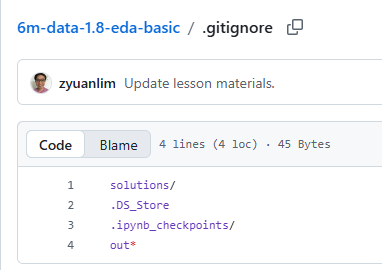

out.csv, out.jason etc only visible in VSC but hidden in Github

## 💻💻 The Catch: What happens if you switch computers?
Because the file is ignored by Git, it only exists on your current machine (or wherever you downloaded the original project).

Tomorrow: You open VS Code on the same computer, and out.csv is still there, ready to use.

If you clone the repo on a new computer: You will download the code and the tracked files, but out.csv will be missing. You will have to run the Python notebook again to re-create it.

If a teammate pulls your code from GitHub: They won't get your out.csv either. They will have to run the code themselves to generate their own version of out.csv.

**Save our session's work.** Everything from Parts 2 and 3 lives in `clean`. Write out the columns
a colleague would actually want.


In [23]:
# 👉 Keep the useful columns, in a sensible order, with the tidy names.

final = clean[[
    "date", "outlet_name", "daypart", "tickets", "items", "revenue_sgd", "staff", "manager",
]].sort_values(["date", "outlet_name", "daypart"])

final.to_csv("../data/cafe_june_clean.csv", index=False)

final.head()


,date,outlet_name,daypart,tickets,items,revenue_sgd,staff,manager
9,2025-06-01,Holland Village,Evening,69.0,96.0,613.92,4.0,Daniel Lim
10,2025-06-01,Holland Village,Midday,57.0,82.0,608.41,4.0,Daniel Lim
11,2025-06-01,Holland Village,Morning,75.0,106.0,478.60,4.0,Daniel Lim
6,2025-06-01,Marina Bay,Evening,7.0,10.0,67.72,1.0,Priya Nair
7,2025-06-01,Marina Bay,Midday,19.0,27.0,207.79,2.0,Priya Nair


In [28]:
# 👉 Beat 4 of the 1.8 habit -- verify. Read back what you just wrote and check it matches.

check = pd.read_csv("../data/cafe_june_clean.csv")

print("rows written:", len(check))
print(f"June revenue: ${check['revenue_sgd'].sum():,.2f}")
print("date column came back as:", check["date"].dtype)


rows written: 360
June revenue: $174,753.07
date column came back as: object


> **Note that last line.** The date went out as a real date and came back as **text**. CSV has no
> way to store types, so every reader has to re-parse them (`parse_dates=["date"]`). Databases and
> pickle files remember types; CSV and JSON forget them. That is worth knowing before you build a
> pipeline out of CSVs.


**Excel export:**


In [35]:
# 👉 Writing Excel needs a 'writer' object when you want control over sheets.
#    Using `with` closes the file for you, which is what actually saves it.

with pd.ExcelWriter("../data/cafe_june_clean.xlsx") as writer:
    final.to_excel(writer, sheet_name="June", index=False)
    june_summary.to_excel(writer, sheet_name="Summary")

pd.ExcelFile("../data/cafe_june_clean.xlsx").sheet_names


['June', 'Summary']

## 💡💡 Create new outlet summary and export to new file 💡💡

In [24]:
## add outlet summary and export to file with different name for testing

outlet_summary = clean.groupby("outlet_name", observed=True).agg(
    revenue=("revenue_sgd", "sum"),
    shifts=("revenue_sgd", "size"),
    avg_shift=("revenue_sgd", "mean"),
    tickets=("tickets", "sum"),
    items=('items',"sum")
)
outlet_summary = outlet_summary.round(2)

display(outlet_summary)

final.to_csv("../data/final.csv", index=False)

with pd.ExcelWriter("../data/final.xlsx") as writer:
    final.to_excel(writer, sheet_name="Jun Rev", index=False)
    outlet_summary.to_excel(writer, sheet_name="Summary with Items")

pd.ExcelFile("../data/final.xlsx").sheet_names

,revenue,shifts,avg_shift,tickets,items
outlet_name,,,,,
Raffles Place,52909.59,90,587.88,6655.0,9621.0
Tampines Mall,44792.84,90,497.70,5080.0,7422.0
Marina Bay,32452.41,90,360.58,4065.0,5934.0
Holland Village,44598.23,90,495.54,5192.0,7536.0


['Jun Rev', 'Summary with Items']

### 4.3: Databases

Most real data lives in a database rather than a file. `sqlalchemy` is the library pandas uses to
talk to them, and the pandas side barely changes.


In [43]:
# 👉 SQLAlchemy speaks to many database engines through one interface.
import sqlalchemy as sqla

# 👉 A connection string says which engine and which file. `sqlite:///` is a local file --
#    no server to install, which is why it is the right thing for a lesson.
cafedb = sqla.create_engine("sqlite:///../data/cafe.db")

# 👉 What tables are in there? `inspect` is the version-safe way to ask.
sqla.inspect(cafedb).get_table_names()


['daily_sales_june', 'june_clean', 'outlets']

In [44]:
# 👉 Give a table name and pandas reads the whole table into a DataFrame.
pd.read_sql_table("outlets", cafedb)


,outlet_id,outlet_name,manager,manager_email
0,OUT-01,Raffles Place,Aisha Rahman,aisha.rahman@dailygrind.sg
1,OUT-02,Tampines Mall,Wei Ming Tan,weiming.tan@dailygrind.sg
2,OUT-03,Marina Bay,Priya Nair,priya.nair@dailygrind.sg
3,OUT-04,Holland Village,Daniel Lim,daniel.lim@dailygrind.com.sg


In [45]:
# 👉 Or hand it real SQL and only the query result comes back. Same DataFrame either way.
#    Everything you learned about SQL in Lessons 1.3-1.5 works here.

outlet_rev = (
    'SELECT outlet_id, SUM(revenue_sgd) AS revenue, COUNT(*) AS shifts '
    'FROM daily_sales_june '
    'GROUP BY outlet_id '
    'ORDER BY revenue DESC'
)

pd.read_sql(outlet_rev, cafedb)


,outlet_id,revenue,shifts
0,OUT-01,53254.98,90
1,OUT-02,44896.12,90
2,OUT-04,44699.83,90
3,OUT-03,32818.26,90


In [46]:
# 👉 Writing back: `to_sql` creates (or replaces) a table from a DataFrame.
#    This is how a cleaned table gets handed to the rest of the business.

final.to_sql("june_clean", cafedb, index=False, if_exists="replace")

sqla.inspect(cafedb).get_table_names()


['daily_sales_june', 'june_clean', 'outlets']

In [47]:
import sqlalchemy as sqla
import pandas as pd

# 1. RECREATE THE ENGINE to cafe.db
cafedb = sqla.create_engine("sqlite:///../data/cafe.db")

# 2. Get the list of table names
cafedb_tables = sqla.inspect(cafedb).get_table_names()
print("Tables in this database:", cafedb_tables)

# 3. Create an empty dictionary to hold the dataframes
all_tables = {}

# 4. Loop through and load them
for table in cafedb_tables:
    all_tables[table] = pd.read_sql_table(table, cafedb)
    print(f"Loaded '{table}': {len(all_tables[table])} rows")

Tables in this database: ['daily_sales_june', 'june_clean', 'outlets']
Loaded 'daily_sales_june': 360 rows
Loaded 'june_clean': 360 rows
Loaded 'outlets': 4 rows


In [48]:
# 💡💡💡 view tables records 💡💡💡
# 1. View the whole 'outlets' table (since it only has 4 rows)
display(all_tables['outlets'])

# 2. Preview the first 5 rows of the 'june_clean' table
display(all_tables['june_clean'].head())

# 3. Preview the last 5 rows of the 'daily_sales_june' table
display(all_tables['daily_sales_june'].tail())

,outlet_id,outlet_name,manager,manager_email
0,OUT-01,Raffles Place,Aisha Rahman,aisha.rahman@dailygrind.sg
1,OUT-02,Tampines Mall,Wei Ming Tan,weiming.tan@dailygrind.sg
2,OUT-03,Marina Bay,Priya Nair,priya.nair@dailygrind.sg
3,OUT-04,Holland Village,Daniel Lim,daniel.lim@dailygrind.com.sg


,date,outlet_name,daypart,tickets,items,revenue_sgd,staff,manager
0,2025-06-01,Holland Village,Evening,69.0,96.0,613.92,4.0,Daniel Lim
1,2025-06-01,Holland Village,Midday,57.0,82.0,608.41,4.0,Daniel Lim
2,2025-06-01,Holland Village,Morning,75.0,106.0,478.60,4.0,Daniel Lim
3,2025-06-01,Marina Bay,Evening,7.0,10.0,67.72,1.0,Priya Nair
4,2025-06-01,Marina Bay,Midday,19.0,27.0,207.79,2.0,Priya Nair


,date,outlet_id,daypart,tickets,items,revenue_sgd
355,2025-06-30,OUT-03,Midday,49,73,497.02
356,2025-06-30,OUT-03,Evening,18,26,170.03
357,2025-06-30,OUT-04,Morning,68,103,455.32
358,2025-06-30,OUT-04,Midday,50,75,515.76
359,2025-06-30,OUT-04,Evening,66,91,619.51


In [49]:
# 💡💡💡 Check for views 💡💡💡

views = sqla.inspect(cafedb).get_view_names()
print("Views in this database:", views)

Views in this database: []


In [50]:
# 💡💡💡 This will show tables, views, indexes, etc -> SQLite normally only has 1 main schema 💡💡💡

all_objects = sqla.inspect(cafedb).get_schema_names()
print(all_objects)

['main']


> **Task:** write a *filtered* table to the database.
> 1. Filter `final` to Marina Bay only.
> 2. Write it to a new table called `marina_june`.
> 3. Read it back with `pd.read_sql` and check the row count is 90 (30 days × 3 dayparts).


In [51]:
# 1. Filter to Marina based on june_clean table records
# (Assuming 'all_tables' dictionary is already loaded as per your previous cell)

june_clean_df = all_tables['june_clean']

# Filter where the outlet name is exactly 'Marina Bay'
marina = june_clean_df[june_clean_df['outlet_name'] == 'Marina Bay'].copy()

print(f"Filtered pandas dataframe: {len(marina)} rows")  # len = rows length

marina


Filtered pandas dataframe: 90 rows


,date,outlet_name,daypart,tickets,items,revenue_sgd,staff,manager
3,2025-06-01,Marina Bay,Evening,7.0,10.0,67.72,1.0,Priya Nair
4,2025-06-01,Marina Bay,Midday,19.0,27.0,207.79,2.0,Priya Nair
5,2025-06-01,Marina Bay,Morning,40.0,59.0,280.20,3.0,Priya Nair
15,2025-06-02,Marina Bay,Evening,18.0,28.0,173.74,2.0,Priya Nair
16,2025-06-02,Marina Bay,Midday,36.0,55.0,394.68,3.0,Priya Nair
...,...,...,...,...,...,...,...,...
340,2025-06-29,Marina Bay,Midday,15.0,22.0,154.99,2.0,Priya Nair
341,2025-06-29,Marina Bay,Morning,35.0,52.0,228.34,3.0,Priya Nair
351,2025-06-30,Marina Bay,Evening,18.0,26.0,170.03,2.0,Priya Nair
352,2025-06-30,Marina Bay,Midday,49.0,73.0,497.02,3.0,Priya Nair


In [52]:
# 2. Write it to a new table called marina_june
# if_exists='replace' is crucial here! It means if you run this cell again, 
# it won't crash; it will just overwrite the old table.

marina.to_sql('marina_june', cafedb, if_exists='replace', index=False)
print("Successfully wrote table 'marina_june' to the database.")

cafedb_tables = sqla.inspect(cafedb).get_table_names()
print("Tables in this database:", cafedb_tables)


Successfully wrote table 'marina_june' to the database.
Tables in this database: ['daily_sales_june', 'june_clean', 'marina_june', 'outlets']


In [53]:
# 3. Read it back with pd.read_sql and check the row count is 90

verify_query = "SELECT * FROM marina_june"
marina_june_check = pd.read_sql(verify_query, cafedb)

print(f"\nRow count marina_june via SQL: {len(marina_june_check)}")
display(marina_june_check.head())



Row count marina_june via SQL: 90


,date,outlet_name,daypart,tickets,items,revenue_sgd,staff,manager
0,2025-06-01 00:00:00.000000,Marina Bay,Evening,7.0,10.0,67.72,1.0,Priya Nair
1,2025-06-01 00:00:00.000000,Marina Bay,Midday,19.0,27.0,207.79,2.0,Priya Nair
2,2025-06-01 00:00:00.000000,Marina Bay,Morning,40.0,59.0,280.20,3.0,Priya Nair
3,2025-06-02 00:00:00.000000,Marina Bay,Evening,18.0,28.0,173.74,2.0,Priya Nair
4,2025-06-02 00:00:00.000000,Marina Bay,Midday,36.0,55.0,394.68,3.0,Priya Nair


> **Final challenge:**
> 1. Read `daily_sales_june` back out of the database.
> 2. Compute total revenue per daypart with SQL (`GROUP BY daypart`) *and* with pandas
>    (`groupby("daypart")`).
> 3. Confirm the two agree. Two tools, one answer — that is the check worth building the habit on.


In [ ]:
# Write the query
june_daily_sales = "SELECT * FROM daily_sales_june"

# Execute the query against the database and save to a new variable
daily = pd.read_sql(june_daily_sales, cafedb) # use pd.read_sql(...) to see the latest data directly from the db

# Display the result
display(daily)

,date,outlet_id,daypart,tickets,items,revenue_sgd
0,2025-06-01,OUT-01,Morning,50,71,324.52
1,2025-06-01,OUT-01,Midday,20,30,205.21
2,2025-06-01,OUT-01,Evening,9,13,78.38
3,2025-06-01,OUT-02,Morning,80,112,557.16
4,2025-06-01,OUT-02,Midday,82,119,932.35
...,...,...,...,...,...,...
355,2025-06-30,OUT-03,Midday,49,73,497.02
356,2025-06-30,OUT-03,Evening,18,26,170.03
357,2025-06-30,OUT-04,Morning,68,103,455.32
358,2025-06-30,OUT-04,Midday,50,75,515.76


In [71]:
# SQL Group BY
daypart_rev = """
SELECT daypart, SUM(revenue_sgd) AS revenue
FROM daily_sales_june
GROUP BY daypart
ORDER BY revenue DESC
"""

rev_daypart = pd.read_sql(daypart_rev, cafedb)
print("\n--- Result from SQL ---")
display(rev_daypart)


# Panda groupby
pandas_result = (
    daily.groupby("daypart")["revenue_sgd"]
    .sum()
    .reset_index()
    .rename(columns={"revenue_sgd": "revenue"})
    .sort_values("revenue", ascending=False)
)

print("\n--- Result from Pandas ---")
display(pandas_result)


--- Result from SQL ---


,daypart,revenue
0,Morning,67918.21
1,Midday,66910.95
2,Evening,40840.03



--- Result from Pandas ---


,daypart,revenue
2,Morning,67918.21
1,Midday,66910.95
0,Evening,40840.03


## 🎯 Wrap-Up

1. **Always run the five-move first look** on a new file — head, shape, info, dtypes, describe.
   It takes two minutes and it found all five of today's problems.
2. **Wrong types hide everything.** The impossible \$98,000 and the -999 sentinels were invisible
   while revenue was text. Move 4 (`.dtypes`) is not paperwork.
3. **Cleaning decisions depend on what the value means**, not on what is convenient: fill, drop,
   cap or mark missing are four different answers to four different situations.
4. **Order of operations matters.** Remove the sentinels *before* you compute the median you are
   going to impute with.
5. **Standardise your keys before you trust a check.** The duplicate check in 2.2 was meaningless
   until the twelve outlet spellings became four.
6. **A clean table is not the goal; a trustworthy answer is.** Section 3.5 — four rows, one per
   café — is what all the cleaning was for.

**Next Steps:**
- Complete the [Assignment](./assignment.md) — audit a second month of the same export.
- Next lesson: **1.9 EDA Advanced** opens `daily_sales.csv` — the same export for **all 18 months**,
  cleaned exactly the way you just cleaned June, and asks what the pattern is.

> **The handoff, in one number.** Your cleaned June total is **\$174,753**. In Lesson 1.9's clean
> 18-month file, June 2025 is **\$175,669** — a difference of **\$916**, or 0.5%, and you can say
> exactly where it comes from: **eight shifts** (four sentinels, one mis-keyed figure and three blanks)
> where you put the median in place of a number this export had destroyed.
>
> That is the difference between clean data and lucky data: not that your figure matches, but that
> you can account for why it does not.


---

## 📎 Appendix — Self-Study

These topics fall outside today's four learning outcomes, but come up constantly in practice.
Deep dives on categorical internals, awkward CSV parsing and pickle files live in `reference.md`.


### Permutation and Random Sampling

Reordering rows, or taking a random subset — the basis of train/test splits later in the course.


In [34]:
# 👉 A 5x7 table of the numbers 0-34 to make row shuffling easy to see.
df = pd.DataFrame(np.arange(5 * 7).reshape((5, 7)))

df


,0,1,2,3,4,5,6
0,0,1,2,3,4,5,6
1,7,8,9,10,11,12,13
2,14,15,16,17,18,19,20
3,21,22,23,24,25,26,27
4,28,29,30,31,32,33,34


In [35]:
# 👉 `permutation(5)` returns the numbers 0-4 in random order -- a shuffled seating plan.
sampler = np.random.default_rng(seed=12345).permutation(5)

sampler


array([4, 3, 0, 2, 1])

In [36]:
# 👉 `.iloc[...]` selects rows *by position*, so the table comes back in the shuffled order.
df.iloc[sampler]


,0,1,2,3,4,5,6
4,28,29,30,31,32,33,34
3,21,22,23,24,25,26,27
0,0,1,2,3,4,5,6
2,14,15,16,17,18,19,20
1,7,8,9,10,11,12,13


In [37]:
# 👉 `.take()` does the same job and reads a little more clearly.
df.take(sampler)


,0,1,2,3,4,5,6
4,28,29,30,31,32,33,34
3,21,22,23,24,25,26,27
0,0,1,2,3,4,5,6
2,14,15,16,17,18,19,20
1,7,8,9,10,11,12,13


Permuting columns:


In [38]:
# 👉 `df.shape[1]` is the number of columns, so this shuffles the column positions.
column_sampler = np.random.default_rng(seed=12345).permutation(df.shape[1])

column_sampler


array([4, 3, 0, 2, 1, 6, 5])

In [39]:
# 👉 `axis=1` applies the shuffle to columns instead of rows.
df.take(column_sampler, axis=1)


,4,3,0,2,1,6,5
0,4,3,0,2,1,6,5
1,11,10,7,9,8,13,12
2,18,17,14,16,15,20,19
3,25,24,21,23,22,27,26
4,32,31,28,30,29,34,33


**Random sample:** getting a random subset without the manual shuffle.


In [40]:
# 👉 `.sample()` skips the manual shuffle: just ask for 3 random rows.
df.sample(n=3)


,0,1,2,3,4,5,6
1,7,8,9,10,11,12,13
4,28,29,30,31,32,33,34
3,21,22,23,24,25,26,27


In [41]:
# 👉 `replace=True` puts each pick back in the hat, so 10 draws from 5 rows is possible
#    and rows can repeat. This is 'sampling with replacement'.
df.sample(n=10, replace=True)


,0,1,2,3,4,5,6
0,0,1,2,3,4,5,6
1,7,8,9,10,11,12,13
2,14,15,16,17,18,19,20
1,7,8,9,10,11,12,13
1,7,8,9,10,11,12,13
2,14,15,16,17,18,19,20
0,0,1,2,3,4,5,6
0,0,1,2,3,4,5,6
0,0,1,2,3,4,5,6
1,7,8,9,10,11,12,13


> **Task:** sample `df` using the parameter `frac` (a fraction of the rows) instead of `n` (a count).


---

## 🏁 Lesson 1.8 Complete!

You've covered all four sections:
- **Part 1:** Descriptive Statistics — summarising a dataset
- **Part 2:** Data Quality — missing values, duplicates, impossible values
- **Part 3:** Data Transformation — mapping, labels, strings, categories, dates
- **Part 4:** Reading & Writing Data — CSV, JSON, Excel, databases

**Next step:** work through `assignment.md` — audit a second month of the same export.
Then open **Lesson 1.9 — EDA Advanced**, which loads `daily_sales.csv`, the same export cleaned this way for all 18 months, and asks what the pattern is.